# Task 3 – k-NN Retrieval and Coverage Curves

Evaluate the embedding model across the four support/test scenarios and reproduce the error–coverage analysis.

## Context
This notebook implements Task 3, where the metric model from Task 2 must be used to build a recommendation system. The feature extractor is applied to four scenarios (main train to main test, main support to main test, new support to new test, and merged support to merged test). For each scenario we compute accuracy and balanced accuracy via k nearest neighbours on the embedding space. The notebook also generates the error versus coverage curve based on the confidence threshold.

In [6]:
from pathlib import Path

import torch
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from torch.utils.data import DataLoader

from fashion_metric import (
    CNET_HHD0_V44,
    evaluate_knn,
    plot_error_coverage_curve,
)
from fashion_metric.data import build_all_datasets

In [7]:
DATASETS = build_all_datasets()
train_loader = DataLoader(DATASETS["train_dataset"], batch_size=32, shuffle=False)
main_test_loader = DataLoader(DATASETS["main_test_dataset"], batch_size=32, shuffle=False)
new_test_loader = DataLoader(DATASETS["new_test_dataset"], batch_size=32, shuffle=False)
main_support_loader = DataLoader(DATASETS["main_support_dataset"], batch_size=32, shuffle=False)
new_support_loader = DataLoader(DATASETS["new_support_dataset"], batch_size=32, shuffle=False)
merged_test_loader = DataLoader(DATASETS["merged_test_dataset"], batch_size=32, shuffle=False)
merged_support_loader = DataLoader(DATASETS["merged_support_dataset"], batch_size=32, shuffle=False)


In [9]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EMBEDDING_WEIGHTS = Path("output/metric_learning/metric_model.pt")
model = CNET_HHD0_V44(num_classes=39, input_shape=(3, 60, 80))
if EMBEDDING_WEIGHTS.exists():
    state_dict = torch.load(EMBEDDING_WEIGHTS, map_location=DEVICE)
    model.load_state_dict(state_dict)
else:
    raise FileNotFoundError(f"Could not find weights at {EMBEDDING_WEIGHTS}. Train Task 2 or update the path.")
model.to(DEVICE)
model.eval()


CNET_HHD0_V44(
  (block1): Sequential(
    (0): Conv2d(3, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.05, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.05, inplace=False)
  )
  (block3): Sequential(
    (0): Conv2d(512, 1024, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0,

In [10]:
scenarios = [
    ("Main train → Main test", train_loader, main_test_loader),
    ("Main support → Main test", main_support_loader, main_test_loader),
    ("New support → New test", new_support_loader, new_test_loader),
    ("Main+New support → Main+New test", merged_support_loader, merged_test_loader),
]

rows = []
for name, support_loader, test_loader in scenarios:
    test_labels, predicted_labels = evaluate_knn(
        support_loader=support_loader,
        test_loader=test_loader,
        model=model,
        k=3,
        device=DEVICE.type,
        name=name,
    )
    rows.append({
        "Scenario": name,
        "Accuracy": accuracy_score(test_labels, predicted_labels),
        "Balanced Accuracy": balanced_accuracy_score(test_labels, predicted_labels),
    })

results_df = pd.DataFrame(rows)
display(results_df)

,Scenario,Accuracy,Balanced Accuracy
0,Main train → Main test,0.912369,0.863030
1,Main support → Main test,0.905859,0.858620
2,New support → New test,0.785542,0.757392
3,Main+New support → Main+New test,0.778507,0.733851


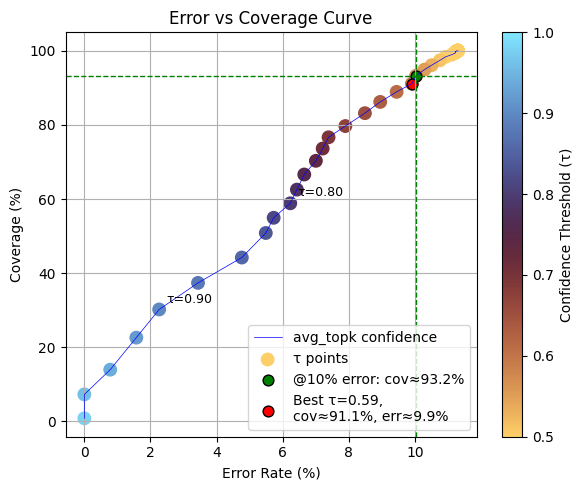

In [11]:
plot_error_coverage_curve(
    model=model,
    test_loader=merged_test_loader,
    support_loader=merged_support_loader,
    device=DEVICE.type,
    k=3,
)